# Clean & restructure agricultural PDFs for RAG — no AI

Rebuilds every PDF in a folder into a clean, organized PDF with the **same file name**, entirely on your computer with ordinary code (no API, no usage, free). It takes a few minutes for the whole folder.

**What it does to each PDF**
- **Fixes the text your model extracts.** Arabic is rebuilt from the glyph positions, so reversed text, broken لا ligatures ("األراضي" → "الأراضي"), legacy presentation-form letters, kashida stretching, reversed Persian digits and numbers displaced inside lines all come out right. Typing habits of Arabic Word files are normalized: ranges written high-to-low ("6-4" → "4-6"), "%15" → "15%", "1,5" → "1.5", and "0" typed as a full stop. Glyphs with no Unicode mapping are filled in from the document's own vocabulary.
- **Removes useless parts.** Cover pages, ministry headers, credits and author pages, ISBN/copyright lines, contents pages, back covers, running headers/footers, page numbers, prefaces/forewords, acknowledgments, reference lists and gibberish from decorative fonts.
- **Organizes the rest.** Detects headings (numbered main sections), paragraphs and bullet lists, and turns ruled tables into one self-contained line per row ("Variety: Giza 171 — Date: … — Seed rate: …").
- **Renders a clean PDF** in the green layout of your improved sugar beet guide: title, summary line, contents, DejaVu Sans embedded. The output is built for extraction: Western digits, no lam-alef ligature glyphs, no bold or italics inside lines, no diacritics.

**What code alone can't do:** rewrite or merge content like a person would. The text stays the source's own wording, with the same order and facts. Headings follow the source's fonts, so a messy source gives imperfect heading levels, and scanned pages without a text layer are skipped.

**Steps:** 1) install → 2) settings → 3) load the engine → 4) test one file → 5) run all → 6) check → 7) replace the originals.
New PDFs go to a separate `…_clean` folder first. Your originals are only overwritten in step 7, and a backup copy is kept unless you turn that off.

## 1. Install (run once)

In [1]:
import sys
%pip install -q pymupdf matplotlib playwright
!"{sys.executable}" -m playwright install chromium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Abdok\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 2. Settings

In [2]:
from pathlib import Path

INPUT_DIR  = Path(r"D:\RAG-20261102T133823Z-1-001")          # folder with the PDFs to clean
OUTPUT_DIR = INPUT_DIR.parent / (INPUT_DIR.name + "_clean")  # new PDFs are written here first

DETECT_TABLES   = True    # turn ruled tables into one line per row (slower on graphics-heavy PDFs)
EXPORT_MARKDOWN = True    # also save a plain Markdown copy of every document in OUTPUT_DIR/_work/md
ONLY_FILES = []           # e.g. ["نشرة-دوار-الشمس.pdf"] to process only some files; empty = all PDFs
FORCE = False             # True = redo files that are already finished
KEEP_BACKUP = True        # step 7 keeps a copy of each original in "<folder>_originals_backup"

## 3. Engine
Run these cells once; nothing needs editing.

In [3]:
import re, unicodedata, difflib, html, bisect
from collections import Counter
import pymupdf

### 1. text from glyphs
Rebuilds each line from glyph positions: fixes reversed Arabic, broken لا ligatures and displaced numbers; normalizes presentation forms, kashida, diacritics and digits.

In [4]:
AR_CHAR = re.compile(r"[؀-ۿݐ-ݿࢠ-ࣿﭐ-﷿ﹰ-﻿]")
LTR_CHAR = re.compile(r"[A-Za-z0-9À-ɏ٠-٩۰-۹]")
DIGIT = re.compile(r"[0-9٠-٩۰-۹]")
HARAKA_ONLY = re.compile(r"^[ً-ٰٟۖ-ۭؐ-ؚ]+$")
NUM_ATTACH = set("%٪°‰+#$€£")
MIRROR = str.maketrans("()[]{}«»", ")(][}{»«")
PH_BASE = 0x100000                         # private-use placeholders for glyphs without a Unicode mapping


def is_ph(c):
    return ord(c) >= PH_BASE


class Glyph:
    __slots__ = ("x0", "x1", "y", "t", "size", "bold", "font")

    def __init__(self, x0, x1, y, t, size, bold, font):
        self.x0, self.x1, self.y, self.t, self.size, self.bold, self.font = x0, x1, y, t, size, bold, font


def page_glyphs(page, unknown=None):
    """Glyphs in drawing order. Ligature components (gid == -1) stay attached to their glyph,
    so a لا ligature keeps its logical letter order."""
    vis, inv = [], []
    for tr in page.get_texttrace():
        d = tr["dir"]
        if abs(d[1]) > 0.1 or d[0] < 0:            # rotated / vertical text
            continue
        target = inv if (tr.get("type") == 3 or tr.get("opacity", 1) == 0) else vis
        font, size = tr["font"], tr["size"]
        bold = bool(tr["flags"] & 16) or bool(re.search(r"bold|black|heavy|semibold|demi", font, re.I))
        for uc, gid, origin, bbox in tr["chars"]:
            ch = chr(uc) if uc > 0 else ""
            if (uc == 0xFFFD or uc <= 0) and gid >= 0 and unknown is not None:
                key = (font, gid)                  # unmapped glyph: placeholder, resolved per document
                if key not in unknown:
                    unknown[key] = chr(PH_BASE + len(unknown))
                ch = unknown[key]
            if gid == -1 and target:
                target[-1].t += ch
                target[-1].x1 = max(target[-1].x1, bbox[2])
                continue
            if not ch or HARAKA_ONLY.match(ch):      # diacritics: dropped (they extract as stray marks)
                continue
            target.append(Glyph(bbox[0], bbox[2], origin[1], ch, size, bold, font))
    out = vis if vis else inv                      # scanned PDFs with an invisible OCR layer
    seen, uniq = set(), []
    for g in out:                                  # same glyph drawn twice (fake bold / shadow)
        k = (g.t, round(g.x0 / max(g.size * 0.25, 0.5)), round(g.y / max(g.size * 0.25, 0.5)))
        if k in seen:
            continue
        seen.add(k); uniq.append(g)
    return uniq


def _cls(t):
    if DIGIT.search(t) and not re.search(r"[^\d\u0660-\u0669\u06F0-\u06F9.,٫٬]", t.strip() or "x"):
        return "L"
    if AR_CHAR.search(t):
        return "R"
    if LTR_CHAR.search(t):
        return "L"
    return "N"


def visual_to_logical(gl):
    """Glyphs sorted left->right on one line -> text in logical (reading) order."""
    seq = []
    for i, g in enumerate(gl):
        if seq and not seq[-1].t.isspace() and not g.t.isspace():
            if g.x0 - gl[i - 1].x1 > 0.22 * max(g.size, 1):          # missing space glyph
                seq.append(Glyph(g.x0, g.x0, g.y, " ", g.size, g.bold, g.font))
        seq.append(g)
    has_ar = any(AR_CHAR.search(g.t) for g in seq)
    cls = [("R" if has_ar else "L") if (g.t and is_ph(g.t[0])) else _cls(g.t) for g in seq]
    for i, g in enumerate(seq):                                      # % ° stick to their number
        s = g.t.strip()
        if cls[i] == "N" and s and s[0] in NUM_ATTACH:
            if (i and DIGIT.search(seq[i - 1].t)) or (i + 1 < len(seq) and DIGIT.search(seq[i + 1].t)):
                cls[i] = "L"
    n_r = cls.count("R")
    n_l = cls.count("L")
    if n_r == 0 or (n_r < 3 and n_l > 1.5 * n_r):
        return "".join(g.t for g in seq), False                     # left-to-right line
    rev = list(range(len(seq)))[::-1]                               # right-to-left line: reverse glyphs,
    out, i = [], 0                                                  # then restore numbers / Latin runs
    while i < len(rev):
        if cls[rev[i]] == "L":
            j, last = i, i
            while j < len(rev) and cls[rev[j]] != "R":
                if cls[rev[j]] == "L":
                    last = j
                j += 1
            out += rev[i:last + 1][::-1]
            i = last + 1
        else:
            out.append(rev[i])
            i += 1
    return "".join(seq[k].t for k in out), True


def normalize(s):
    s = unicodedata.normalize("NFKC", s)
    s = s.replace("ـ", "")                                     # kashida
    s = s.translate(str.maketrans("یکۀ", "يكه"))                    # Persian letter forms
    s = re.sub(r"[ً-ٰٟ]", "", s)                      # diacritics
    s = re.sub(r"[​-‏‪-‮⁦-⁩﻿\x00-\x08\x0b-\x1f]", "", s)
    s = s.translate(str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹٫٪", "01234567890123456789.%"))
    s = re.sub(r"[ \t  - ]+", " ", s)
    return s.strip()


_RANGE = re.compile(r"(?<![\d.\-–])(\d+(?:\.\d+)?)\s*([-–])\s*(\d+(?:\.\d+)?)(?!\d|\.\d|\s*[-–]\s*\d)")


def fix_arabic_line(s):
    """Typing conventions of Arabic Word documents."""
    s = re.sub(r"(?<=\d),(?=\d{1,2}(?!\d))", ".", s)                 # 1,5 -> 1.5
    def swap(m):
        a, d, b = m.group(1), m.group(2), m.group(3)
        return f"{b}{d}{a}" if float(a) > float(b) else f"{a}{d}{b}"  # ranges are written high-low
    s = _RANGE.sub(swap, s)
    s = re.sub(r"%\s*(\d+(?:\.\d+)?(?:[-–]\d+(?:\.\d+)?)?)", r"\1%", s)  # %15 -> 15%
    s = re.sub(r"(?<![\d.])0{3,}(?![\d.])", "…", s)
    s = re.sub(r"(?<=[؀-ۿ)\s])\s*(?<![\d.])0\s*$", ".", s)    # "0" typed as a full stop
    s = re.sub(r"(?<=[؀-ۿ)])\s+0\s+(?=[؀-ۿ(])", ". ", s)
    if s in ("0", "00"):
        s = "."
    return s.strip()

### 2. lines & blocks
Groups glyphs into lines and blocks (merging justified-line pieces).

In [5]:
def _family(font):
    f = font.split("+")[-1]
    f = re.split(r"[-,]", f)[0]
    return re.sub(r"(PSMT|PS|MT|Bold|Italic|Regular)+$", "", f, flags=re.I).lower()


def _mode(vals):
    return Counter(vals).most_common(1)[0][0] if vals else None


def glyph_lines(glyphs):
    """Cluster loose glyphs into lines (used for table cells)."""
    gl = sorted(glyphs, key=lambda g: g.y)
    lines, cur = [], []
    for g in gl:
        if cur and abs(g.y - cur[-1].y) > 0.45 * max(g.size, 1):
            lines.append(cur); cur = []
        cur.append(g)
    if cur:
        lines.append(cur)
    out = []
    for ln in lines:
        ln.sort(key=lambda g: (g.x0 + g.x1) / 2)
        txt, rtl = visual_to_logical(ln)
        txt = normalize(txt)
        if rtl:
            txt = fix_arabic_line(txt)
        if txt:
            out.append((txt, rtl))
    return out


def page_lines(page, glyphs, exclude_rects=()):
    glyphs = sorted(glyphs, key=lambda g: g.y)
    ys = [g.y for g in glyphs]
    used = bytearray(len(glyphs))
    rd = page.get_text("rawdict")
    W, H = page.rect.width, page.rect.height
    blocks = []
    for b in rd["blocks"]:
        if b["type"] != 0:
            continue
        # MuPDF splits justified lines at wide gaps: merge pieces that share a baseline into one visual line
        rows = []
        for l in b["lines"]:
            r = pymupdf.Rect(l["bbox"])
            if any(r.intersects(e) and (r & e).get_area() > 0.5 * r.get_area() for e in exclude_rects):
                continue
            for i, row in enumerate(rows):
                h = min(r.height, row.height) or 1
                if min(r.y1, row.y1) - max(r.y0, row.y0) > 0.6 * h:
                    rows[i] = pymupdf.Rect(min(row.x0, r.x0), min(row.y0, r.y0), max(row.x1, r.x1), max(row.y1, r.y1))
                    break
            else:
                rows.append(r)
        lines = []
        for r in rows:
            x0, y0, x1, y1 = r
            lo, hi = bisect.bisect_left(ys, y0 - 1.5), bisect.bisect_right(ys, y1 + 1.5)
            mem = []
            for k in range(lo, hi):
                if used[k]:
                    continue
                g = glyphs[k]
                if x0 - 1.5 <= (g.x0 + g.x1) / 2 <= x1 + 1.5:
                    mem.append(g); used[k] = 1
            if not mem:
                continue
            mem.sort(key=lambda g: (g.x0 + g.x1) / 2)
            raw, rtl = visual_to_logical(mem)
            text = normalize(raw)
            if rtl:
                text = fix_arabic_line(text)
            if not text:
                continue
            vis = [g for g in mem if g.t.strip()]
            lines.append({
                "text": text, "rtl": rtl, "bbox": (x0, y0, x1, y1),
                "size": round(_mode([round(g.size * 2) / 2 for g in vis]) or 0, 1),
                "bold": sum(g.bold for g in vis) >= 0.6 * max(1, len(vis)),
                "family": _mode([_family(g.font) for g in vis]) or "",
                "W": W, "H": H,
            })
        if lines:
            blocks.append({"bbox": b["bbox"], "lines": lines})
    return blocks


AR_CANDIDATES = ["", "لا", "لأ", "لإ", "لآ"] + list("ابتثجحخدذرزسشصضطظعغفقكلمنهويةىأإآئؤء")
LAT_CANDIDATES = ["", "fi", "fl", "ff", "ffi", "ffl", "-", "'", "•"]
WORD = re.compile(r"[\w\U00100000-\U0010FFFD]+")


def resolve_placeholders(texts, placeholders):
    """Pick, for every unmapped glyph, the letter(s) that turn its words into words used elsewhere in the
    same document ("" for stretching/kashida glyphs, "لا" for unmapped lam-alef ligatures, ...)."""
    vocab, occ = Counter(), {ph: [] for ph in placeholders}
    for t in texts:
        for w in WORD.findall(t):
            phs = [c for c in w if is_ph(c)]
            if not phs:
                vocab[w] += 1
            else:
                for ph in set(phs):
                    if ph in occ and len(occ[ph]) < 400:
                        occ[ph].append(w)
    mapping = {}
    for ph, words in occ.items():
        if not words:
            mapping[ph] = ""; continue
        arabic = sum(1 for w in words if AR_CHAR.search(w)) >= len(words) / 2
        best, best_score = None, -1
        for c in (AR_CANDIDATES if arabic else LAT_CANDIDATES):
            score = 0
            for w in words:
                test = "".join(c if x == ph else ("" if is_ph(x) else x) for x in w)
                score += vocab.get(test, 0) > 0
            if score > best_score:
                best, best_score = c, score
        if best_score < max(2, 0.15 * len(words)):
            mid = sum(1 for w in words if w.find(ph) > 0 and w.find(ph) < len(w) - 1) / len(words)
            best = "" if (mid > 0.6 or not arabic) else "لا"
        mapping[ph] = best
    # words that still are not real words: try every candidate for that word alone
    overrides = {}
    for ph, words in occ.items():
        arabic = sum(1 for w in words if AR_CHAR.search(w)) >= max(1, len(words)) / 2
        for w in set(words):
            plain = "".join(mapping.get(x, "") if is_ph(x) else x for x in w)
            if vocab.get(plain, 0):
                continue
            scored = []
            for c in (AR_CANDIDATES if arabic else LAT_CANDIDATES):
                test = "".join(c if x == ph else (mapping.get(x, "") if is_ph(x) else x) for x in w)
                if vocab.get(test, 0) >= 2:
                    scored.append((vocab[test], test))
            if scored:
                overrides[w] = max(scored)[1]
    return mapping, overrides

### 3. tables
Ruled tables become one self-contained line per row; also resolves glyphs that have no Unicode mapping using the document's own vocabulary.

In [6]:
def _ruled_segments(page):
    n = 0
    for path in page.get_drawings():
        for it in path["items"]:
            if it[0] == "l":
                a, b = it[1], it[2]
                if abs(a.y - b.y) < 1 or abs(a.x - b.x) < 1:
                    n += 1
            elif it[0] == "re":
                n += 4
        if n >= 8:
            return True
    return False


def page_tables(page, glyphs):
    """Ruled tables -> list of (bbox, rows[list of cell texts], rtl)."""
    out = []
    try:
        if not _ruled_segments(page):
            return out
        found = page.find_tables()
    except Exception:
        return out
    if not found.tables:
        return out
    gs = sorted(glyphs, key=lambda g: g.y)
    ys = [g.y for g in gs]
    for tab in found.tables:
        rows = []
        for r in tab.rows:
            cells = []
            for c in r.cells:
                if c is None:
                    cells.append(None); continue
                x0, y0, x1, y1 = c
                lo, hi = bisect.bisect_left(ys, y0), bisect.bisect_right(ys, y1 + 4)
                inside = [g for g in gs[lo:hi] if x0 <= (g.x0 + g.x1) / 2 <= x1 and y0 <= g.y - 0.3 * g.size <= y1]
                lines = glyph_lines(inside)
                cells.append(" ".join(t for t, _ in lines))
            rows.append(cells)
        if len(rows) < 2 or max(len(r) for r in rows) < 2:
            continue
        texts = [c for r in rows for c in r if c]
        if not texts or sum(len(t) for t in texts) / len(texts) > 220:
            continue                                   # a page frame, not a data table
        rtl = sum(len(AR_CHAR.findall(t)) for t in texts) > sum(len(re.findall(r"[A-Za-z]", t)) for t in texts)
        if rtl:
            rows = [r[::-1] for r in rows]             # first column = rightmost column
        for ci in range(max(len(r) for r in rows)):   # merged cells: carry the value down
            prev = None
            for r in rows:
                if ci < len(r):
                    if r[ci] is None:
                        r[ci] = prev
                    else:
                        prev = r[ci]
        out.append((pymupdf.Rect(tab.bbox), rows, rtl))
    return out


def table_to_items(rows):
    rows = [[(c or "").strip() for c in r] for r in rows]
    rows = [r for r in rows if any(r)]
    if not rows:
        return []
    header = rows[0]
    has_header = all(header) and all(len(h) <= 60 for h in header) and len(rows) > 1
    items = []
    for r in (rows[1:] if has_header else rows):
        vals = [v for v in r if v]
        if len(vals) == 1:
            items.append(vals[0]); continue
        if has_header:
            parts = [f"{h.rstrip(' :')}: {v}" for h, v in zip(header, r) if v]
        else:
            parts = vals
        line = parts[0]
        for prev, part in zip(parts, parts[1:]):
            line += (" " if prev.rstrip().endswith((":", "：")) else " — ") + part
        items.append(line)
    return items

### 4. noise rules
Patterns for page furniture and front matter.

In [7]:
GLOBAL_DROP = re.compile(
    r"(@[\w.-]+\.\w+|https?://|www\.|\bISBN\b|\bISSN\b|\bDOI\b|doi\.org|Corresponding\s+author|©|"
    r"All\s+rights\s+reserved|Copyright|\bReceived\s*:|\bAccepted\s*:|\bPublished\s+online|"
    r"\bTel\s*[:.]|\bFax\s*[:.]|P\.?\s?O\.?\s?Box|تطلب\s*بالمجان|مع\s*تحيات|رقم\s*الإيداع|الترقيم\s*الدولي|"
    r"حقوق\s*الطبع|جميع\s*الحقوق\s*محفوظة)", re.I)
FRONT_KW = re.compile(
    r"([اإ]دارة\s*المركزية|جمهورية\s*مصر|وزارة\s*الزراعة|مركز\s*البحوث|الإدارة\s*المركزية|الادارة\s*المركزية|قطاع\s*الإرشاد|"
    r"المادة\s*العلمية|^\s*إعداد|^\s*اعداد|المشرف\s*العام|رئيس\s*التحرير|مدير\s*التحرير|الإخراج\s*الفني|"
    r"الاخراج\s*الفني|التوزيع|تصميم|مراجعة|ترجمة|معهد\s*بحوث|طبعة|نشرة\s*رقم|^\s*\d{4}\s*/\s*\d{4}\s*$|"
    r"\bAuthors?\b|\bEdited\s+by\b|\bPrepared\s+by\b|\bEdition\b|\bPublisher|\bPrinted\b|University|"
    r"Institute|Department|Faculty|Ministry|Organization|\bCollege\b|Title\s*ID|\bPrice\b|M\.\s?Sc|Ph\.\s?D|B\.\s?Sc|"
    r"reproduced|permission|publishers?\b|trademarks?|Co-?authors?|professor|lecturer|\bassistant\b|"
    r"سكرتارية|التحرير|\.indd|نسخة|document\s+control|research\s+corpus|knowledge\s+base\s*·|بطاقة\s*الإصدار|حدود\s*الاستخدام)", re.I)
NAME_LINE = re.compile(r"^\s*(أ\s?\.?\s?د|ا\s?\.\s?د|د\s?\.|د\s?/|م\s?/|م\s?\.|أ\s?/|Prof\.?|Dr\.?|Mr\.?|Mrs\.?|Ms\.?|Miss\.?|Eng\.?)(\s|/|$)")
TOC_HEAD = re.compile(r"^\s*(فهرس|الفهرس|المحتويات|محتويات|Contents|Table\s+of\s+Contents|CONTENTS|Index)\s*:?\s*$", re.I)
TOC_LINE = re.compile(r"(\.{4,}|…{2,}|_{4,}|\s\d{1,3}\s*$|^\s*\d{1,3}\s+\S)")
PAGE_NUM = re.compile(r"^[\s\-–—|]*(page|صفحة)?\s*[\divxlcIVXLC]{1,6}(\s*(/|of|من)\s*\d+)?[\s\-–—|]*$", re.I)
HARD_DROP = re.compile(r"^\s*(\d+[.\-)]?\s*)?(references?|literature\s+cited|bibliography|works\s+cited|المراجع|مراجع|المصادر|المراجع\s+العلمية)\s*:?\s*$", re.I)
DROP_SECTION = re.compile(
    r"^\s*(\d+[.\-)]?\s*)?(references?|literature\s+cited|bibliography|works\s+cited|acknowledge?ments?|"
    r"foreword|preface|المراجع|مراجع|المصادر|المراجع\s+العلمية|شكر\s*و?\s*تقدير|تقديم|إهداء|اهداء|"
    r"contents|table\s+of\s+contents|المحتويات|الفهرس|فهرس|required\s+citation|research\s+and\s+writing\s+team|"
    r"writing\s+team|project\s+team|background\s+papers|additional\s+(external\s+contributions|fao\s+inputs)|"
    r"(fao\s+)?advisory\s+group|steering\s+committee|editorial\s+(board|team)|photo\s+credits|"
    r"فريق\s*(العمل|الإعداد|الصياغة|المشروع)|لجنة\s*التوجيه|هيئة\s*التحرير)\s*:?\s*$", re.I)
BULLET = re.compile(r"^\s*([•●▪■◆◇○◦►▶➢➤✓✔❖∙·\*]|[-–—](?=\s*\S))\s*")
NUMBERED = re.compile(r"^\s*(\(?\d{1,2}[\-.)]|\(\d{1,2}\)|[أابجدهوزحطيكلمن](?:ـ)?\s?[\-)]|[a-hA-H][.)])\s+")
TERMINAL = tuple(".:؟?!؛…")
LEAD_IN = {"الى", "إلى", "في", "فى", "على", "علي", "من", "عن", "مثل", "وهي", "وهى", "هي", "هى", "وهما", "كالتالي",
           "كالتالى", "التالي", "التالية", "الآتي", "الاتي", "الآتية", "يلي", "يلى", "منها", "أهمها", "اهمها"}


SYMS = re.compile(r"[\u00A0-\u00BF\u00C0-\u024F\u2000-\u22FF\u25A0-\u25FF<>\[\]{}^~|\\¬]")
AUTHOR_LINE = re.compile(r"(\b[A-Z]{1,2}[a-z]?\.\s?){2,}")


def is_gibberish(t, arabic_doc):
    """Text from symbol/decorative fonts without a Unicode map."""
    if AR_CHAR.search(t):
        return False
    n = len(t.strip()) or 1
    sym = len(SYMS.findall(t))
    if arabic_doc:
        return sym >= 0.25 * n or bool(re.fullmatch(r"\s*[A-Za-z]{1,3}\s*", t))
    return n > 5 and sym >= 0.4 * n


def _key(text):
    return re.sub(r"[\W\d_]+", "", text.lower())[:50]

### 5. document assembly
Removes covers/credits/contents/back covers, running headers and page numbers; builds paragraphs, headings and lists; drops prefaces, acknowledgments and references.

In [8]:
def extract_document(path, use_tables=True, log=None):
    doc = pymupdf.open(path)
    n = doc.page_count
    pages, unknown = [], {}
    for pno in range(n):
        page = doc[pno]
        glyphs = page_glyphs(page, unknown)
        tables = page_tables(page, glyphs) if use_tables else []
        blocks = page_lines(page, glyphs, exclude_rects=[t[0] for t in tables])
        items = [{"type": "block", "y": b["bbox"][1], "lines": b["lines"]} for b in blocks]
        items += [{"type": "table", "y": t[0].y0, "rows": t[1], "rtl": t[2]} for t in tables]
        items.sort(key=lambda it: it["y"])
        # keep MuPDF's block order (handles columns) but slot tables in by position
        ordered, tabs = [], [it for it in items if it["type"] == "table"]
        for it in [it for it in items if it["type"] == "block"]:
            while tabs and tabs[0]["y"] <= it["y"]:
                ordered.append(tabs.pop(0))
            ordered.append(it)
        ordered += tabs
        pages.append({"pno": pno, "items": ordered, "W": page.rect.width, "H": page.rect.height})
    meta_title = (doc.metadata or {}).get("title", "") or ""
    doc.close()

    if unknown:                                    # resolve unmapped glyphs from the document's own vocabulary
        texts = [ln["text"] for pg in pages for it in pg["items"] if it["type"] == "block" for ln in it["lines"]]
        texts += [c for pg in pages for it in pg["items"] if it["type"] == "table" for r in it["rows"] for c in r if c]
        mapping, overrides = resolve_placeholders(texts, set(unknown.values()))
        trans = str.maketrans(mapping)

        def fix(t):
            if not t or not any(is_ph(c) for c in t):
                return t
            t = WORD.sub(lambda m: overrides.get(m.group(0), m.group(0)), t)
            return re.sub(r"\s+", " ", t.translate(trans)).strip()
        for pg in pages:
            for it in pg["items"]:
                if it["type"] == "block":
                    for ln in it["lines"]:
                        ln["text"] = fix(ln["text"])
                    it["lines"] = [ln for ln in it["lines"] if ln["text"]]
                else:
                    it["rows"] = [[fix(c) for c in r] for r in it["rows"]]

    # --- running headers / footers / page numbers
    zone_keys = Counter()
    for pg in pages:
        seen = set()
        for it in pg["items"]:
            if it["type"] != "block":
                continue
            for ln in it["lines"]:
                y0, y1 = ln["bbox"][1], ln["bbox"][3]
                if y1 < 0.12 * pg["H"] or y0 > 0.88 * pg["H"]:
                    k = _key(ln["text"])
                    if len(k) >= 3 and k not in seen:
                        seen.add(k); zone_keys[k] += 1
    min_rep = max(3, int(0.2 * n))
    frequent = [k for k, c in zone_keys.items() if c >= min_rep]

    def is_furniture(ln, H):
        y0, y1 = ln["bbox"][1], ln["bbox"][3]
        in_zone = y1 < 0.12 * H or y0 > 0.88 * H
        if (y1 < 0.16 * H or y0 > 0.84 * H) and PAGE_NUM.match(ln["text"]):
            return True
        if in_zone:
            k = _key(ln["text"])
            if k in frequent or any(len(k) >= 6 and difflib.SequenceMatcher(None, k, f).ratio() > 0.8 for f in frequent):
                return True
        return False

    all_text = " ".join(ln["text"] for pg in pages for it in pg["items"] if it["type"] == "block" for ln in it["lines"])
    arabic_doc = len(AR_CHAR.findall(all_text)) > len(re.findall(r"[A-Za-z]", all_text))
    for pg in pages:
        for it in pg["items"]:
            if it["type"] == "block":
                it["lines"] = [ln for ln in it["lines"] if not is_furniture(ln, pg["H"])
                               and not GLOBAL_DROP.search(ln["text"]) and not is_gibberish(ln["text"], arabic_doc)
                               and not re.search(r"(\.{6,}|…{3,}|_{6,})\s*\d{0,4}\s*$|^\s*\d{0,4}\s*(\.{6,}|…{3,})", ln["text"])]

    # --- title candidates from the first pages (largest text that is not front-matter boilerplate)
    def title_from(pg_list):
        cands = []
        for pg in pg_list:
            for it in pg["items"]:
                if it["type"] != "block":
                    continue
                for ln in it["lines"]:
                    t = ln["text"]
                    if (len(_key(t)) >= 3 and not FRONT_KW.search(t) and not NAME_LINE.match(t) and not TOC_HEAD.match(t)
                            and not re.fullmatch(r"[\d\s/\-.]+", t) and len(t) <= 120 and not AUTHOR_LINE.search(t)):
                        cands.append((ln["size"], pg["pno"], ln["bbox"][1], t))
        if not cands:
            return ""
        big = max(c[0] for c in cands)
        first = min(c[1] for c in cands if c[0] == big)
        parts, seen = [], set()
        for c in sorted(cands, key=lambda c: (c[1], c[2])):
            if c[1] == first and c[0] >= 0.6 * big and c[3] not in seen and c[0] > 0:
                seen.add(c[3]); parts.append(c[3])
        t = " ".join(parts[:4])
        if len(t) > 220:
            t = t[:220].rsplit(" ", 1)[0] + " …"
        return t

    # --- front matter pages (cover, credits, TOC) and back cover
    def page_stats(pg):
        lines = [ln for it in pg["items"] if it["type"] == "block" for ln in it["lines"]]
        chars = sum(len(ln["text"]) for ln in lines) + sum(len(c or "") for it in pg["items"] if it["type"] == "table" for r in it["rows"] for c in r)
        fm = sum(1 for ln in lines if FRONT_KW.search(ln["text"]) or NAME_LINE.match(ln["text"]))
        toc = sum(1 for ln in lines if TOC_LINE.search(ln["text"]))
        has_toc_head = any(TOC_HEAD.match(ln["text"]) for ln in lines[:6])
        return {"chars": chars, "lines": len(lines), "fm": fm / max(1, len(lines)),
                "toc": has_toc_head and toc >= 3 or (len(lines) >= 6 and toc / len(lines) > 0.6)}

    stats = [page_stats(pg) for pg in pages]
    drop = set()
    for i in range(min(n, 8)):                                        # leading run
        s = stats[i]
        if s["chars"] < 250 or s["fm"] >= 0.4 or s["toc"]:
            drop.add(i)
        else:
            break
    for i in range(min(n, 10)):                                       # credits / TOC pages further in
        s = stats[i]
        if s["fm"] >= 0.5 or s["toc"]:
            drop.add(i)
    for i in range(n - 1, max(n - 4, -1), -1):                         # back cover
        s = stats[i]
        if s["chars"] < 250 or s["fm"] >= 0.4:
            drop.add(i)
        else:
            break
    if len(drop) >= n:                                                # never drop everything
        drop = set()
    title = title_from(pages[:2] if 0 in drop else pages[:1])

    content = [pg for pg in pages if pg["pno"] not in drop]

    # research papers: on the first content page, drop author/affiliation lines above "Abstract"
    if content:
        pg = content[0]
        flat = [(it, ln) for it in pg["items"] if it["type"] == "block" for ln in it["lines"]]
        abs_i = next((k for k, (_, ln) in enumerate(flat) if re.match(r"^\s*(abstract|summary|الملخص|ملخص|المستخلص)\b", ln["text"], re.I)), None)
        if abs_i is not None and abs_i > 0:
            above = flat[:abs_i]
            big = max(ln["size"] for _, ln in above)
            keep_title = [ln["text"] for _, ln in above if ln["size"] >= big - 0.6]
            if keep_title and not title:
                title = " ".join(keep_title)
            for it, ln in above:
                it["lines"] = [x for x in it["lines"] if x is not ln]

    if content:                                    # author / affiliation lines on the first content page
        lim = 80 if arabic_doc else 160
        for it in content[0]["items"]:
            if it["type"] == "block":
                it["lines"] = [ln for ln in it["lines"] if not (len(ln["text"]) < lim and (
                    FRONT_KW.search(ln["text"]) or NAME_LINE.match(ln["text"]) or
                    (not arabic_doc and AUTHOR_LINE.search(ln["text"]) and len(re.findall(r"\b[a-z]{3,}\b", ln["text"])) <= 4)))]

    # --- body style
    style_chars = Counter()
    for pg in content:
        for it in pg["items"]:
            if it["type"] == "block":
                for ln in it["lines"]:
                    style_chars[(ln["family"], ln["size"], ln["bold"])] += len(ln["text"])
    body_style = style_chars.most_common(1)[0][0] if style_chars else ("", 0, False)
    body_size = body_style[1]

    # --- paragraphs
    # typical line pitch per font size (baseline-to-baseline distance inside running text)
    pitch = {}
    for pg in content:
        for it in pg["items"]:
            if it["type"] != "block":
                continue
            ls = it["lines"]
            for a, b in zip(ls, ls[1:]):
                if a["size"] == b["size"]:
                    d = b["bbox"][1] - a["bbox"][1]
                    if 0 < d < 4 * max(a["size"], 1):
                        pitch.setdefault(a["size"], []).append(d)
    pitch = {k: sorted(v)[len(v) // 2] for k, v in pitch.items() if len(v) >= 3}

    def head_like(t):
        return bool(re.search(r"(:-?|-:)\s*$", t)) and len(t.split()) <= 7

    paras = []   # dict(kind, text, style, rtl, lines, page)
    for pg in content:
        cur = None
        for it in pg["items"]:
            if it["type"] == "table":
                paras.append({"kind": "table", "rows": it["rows"], "rtl": it["rtl"], "page": pg["pno"]})
                cur = None
                continue
            for ln in it["lines"]:
                style = (ln["family"], ln["size"], ln["bold"])
                start = cur is None or cur.get("closed")
                if not start:
                    last = cur["lines"][-1]
                    lh = max(1.0, last["bbox"][3] - last["bbox"][1])
                    step = ln["bbox"][1] - last["bbox"][1]
                    normal = pitch.get(last["size"], 1.25 * lh)
                    width_max = max(l["bbox"][2] - l["bbox"][0] for l in cur["lines"])
                    last_w = last["bbox"][2] - last["bbox"][0]
                    ov = min(ln["bbox"][2], last["bbox"][2]) - max(ln["bbox"][0], last["bbox"][0])
                    if (style != cur["style"] or step > 1.35 * normal or step < 0.3 * lh
                            or BULLET.match(ln["text"]) or NUMBERED.match(ln["text"])
                            or (last["text"].endswith(TERMINAL) and (last_w < 0.85 * width_max or head_like(ln["text"])))
                            or ov < 0.3 * min(last_w, ln["bbox"][2] - ln["bbox"][0])):
                        start = True
                if ln["text"] in (".", "…") and cur is not None:
                    cur["lines"].append(ln)                     # a lone full stop belongs to the previous line
                    continue
                if start:
                    cur = {"kind": "p", "lines": [ln], "style": style, "rtl": ln["rtl"], "page": pg["pno"]}
                    paras.append(cur)
                else:
                    cur["lines"].append(ln)
                if len(cur["lines"]) == 1 and head_like(ln["text"]):
                    cur["closed"] = True                        # a "label:" line stands alone
    for p in paras:
        if p["kind"] != "p":
            continue
        txt = ""
        for ln in p["lines"]:
            t = ln["text"]
            if not txt:
                txt = t
            elif t in (".", "…"):
                txt = txt.rstrip(" .") + t
            elif not p["rtl"] and txt.endswith("-") and t[:1].islower():
                txt = txt[:-1] + t                                     # de-hyphenate English
            else:
                txt += " " + t
        p["text"] = re.sub(r"\s+", " ", txt).strip()

    # join paragraphs broken by page breaks
    merged = []
    for p in paras:
        if (merged and p["kind"] == "p" and merged[-1]["kind"] == "p" and p["page"] != merged[-1]["page"]
                and p["style"] == merged[-1]["style"] and not merged[-1]["text"].endswith(TERMINAL)
                and not BULLET.match(p["text"]) and not NUMBERED.match(p["text"])
                and len(merged[-1]["text"]) > 60):
            merged[-1]["text"] += " " + p["text"]
            merged[-1]["lines"] += p["lines"]
        else:
            merged.append(p)
    paras = [p for p in merged if p["kind"] == "table" or p["text"]]

    NOTE = re.compile(r"^\s*(ملحوظة|ملحوظه|ملاحظة|ملاحظات|تنبيه|هام|تحذير|note|notes|n\.?b\.?)\s*[:\-–]*\s*$", re.I)
    folded = []
    for p in paras:
        if folded and folded[-1].get("note") and p["kind"] == "p":
            p["text"] = folded.pop()["text"].strip(" :-–") + ": " + p["text"]
        if p["kind"] == "p" and NOTE.match(p["text"]):
            p["note"] = True
        folded.append(p)
    paras = folded

    # mirrored brackets (some producers store the visual glyph): fix per paragraph
    for p in paras:
        if p["kind"] == "p" and p["rtl"]:
            t = p["text"]
            o, c = t.find("("), t.find(")")
            if c != -1 and (o == -1 or c < o) and t.count("(") == t.count(")"):
                p["text"] = t.translate(MIRROR)

    # --- headings
    def words(t):
        return len(t.split())

    def heading_candidate(p):
        t = p["text"]
        if p["kind"] != "p" or len(p["lines"]) > 2 or len(t) > 90 or words(t) > 12:
            return None
        if not re.search(r"[A-Za-z؀-ۿ]", t) or t.endswith((".", "،", ",", ";", "؛")):
            return None
        letters = re.findall(r"[A-Za-z؀-ۿ]", t)
        if len(letters) < 3 or t[:1].islower() or t.lower() in ("the", "and", "of", "in", "for", "with", "to"):
            return None
        lastw = re.sub(r"[\s:\-–]+$", "", t).split()[-1:] or [""]
        if lastw[0] in LEAD_IN or (t.startswith("و") and words(t) > 3):
            return None                            # a lead-in sentence ("… تؤدى الى:"), not a heading
        fam, size, bold = p["style"]
        styled = size >= body_size + 0.8 or (bold and not body_style[2]) or (fam != body_style[0] and size >= body_size - 0.6)
        colon = bool(re.search(r"(:-?|-:|:)\s*$", t)) and words(t) <= 7 and len(p["lines"]) == 1
        last = re.sub(r"[\s:\-]+$", "", t).split()[-1:] or [""]
        if colon and (last[0] in LEAD_IN or (t.startswith("و") and words(t) > 3) or
                      re.search(r"(following|include|includes|are|is|as follows|such as)\s*:\s*$", t, re.I)):
            colon = False
        if BULLET.match(t):
            return "bullet-colon" if colon else None
        if NUMBERED.match(t) and not colon and not styled:
            return None
        if styled:
            return "style"
        if colon:
            return "colon"
        return None

    for p in paras:
        p["hc"] = heading_candidate(p) if p["kind"] == "p" else None
    total_p = sum(1 for p in paras if p["kind"] == "p")
    style_count = Counter(p["style"] for p in paras if p["hc"] == "style")
    hstyles = [s for s, c in style_count.items() if c <= 0.4 * total_p]
    hstyles.sort(key=lambda s: (-s[1], not s[2], -style_count[s]))
    sizes = []
    for s in hstyles:                                                  # one level per size bucket
        if not sizes or all(abs(s[1] - z) > 0.6 for z in sizes):
            sizes.append(s[1])
    def size_level(sz):
        for i, z in enumerate(sizes):
            if abs(sz - z) <= 0.6:
                return min(2 + i, 4)
        return 4
    deepest = min(2 + len(sizes), 4) if sizes else 3
    for p in paras:
        hc = p.get("hc")
        if hc == "style" and p["style"] in hstyles:
            p["kind"], p["level"] = "h", size_level(p["style"][1])
        elif hc == "colon":
            p["kind"], p["level"] = "h", deepest if sizes else 3
        elif hc == "bullet-colon":
            p["kind"], p["level"] = "h", 4
        if p["kind"] == "h":
            t = BULLET.sub("", p["text"])
            t = re.sub(r"^\s*[:\-–]+\s*|\s*[:\-–]+\s*$", "", t)
            p["text"] = t.strip() or p["text"]
    # promote so the top level used is h2
    levels = sorted({p["level"] for p in paras if p["kind"] == "h"})
    if levels and levels[0] > 2:
        shift = levels[0] - 2
        for p in paras:
            if p["kind"] == "h":
                p["level"] -= shift

    for _ in range(2):
        cnt = Counter(p["level"] for p in paras if p["kind"] == "h")
        nxt = min((l for l in cnt if l > 2), default=None)
        if cnt.get(2, 0) < 3 and nxt is not None and cnt[nxt] >= 4:
            for p in paras:
                if p["kind"] == "h" and p["level"] > 2:
                    p["level"] -= 1
    ORD = re.compile(r"^\s*(أولا|ثانيا|ثالثا|رابعا|خامسا|سادسا|سابعا|ثامنا|تاسعا|عاشرا|first|second|third|fourth|fifth)\b", re.I)
    base, base_style = 2, None
    for p in paras:
        if p["kind"] != "h":
            continue
        numbered = NUMBERED.match(p["text"]) or ORD.match(p["text"]) or re.match(r"^\s*\d{1,2}\s*[-.)]\s*\S", p["text"])
        if numbered and p["style"] == base_style and p["level"] <= base:
            p["level"] = min(4, base + 1)          # "1- …" under a heading of the same look = subsection
        elif not numbered:
            base, base_style = p["level"], p["style"]

    # --- drop prefaces / acknowledgments / references / leftover contents sections
    out, skip_level, skip_hard = [], None, False
    for p in paras:
        is_head = p["kind"] == "h" or (p["kind"] == "p" and len(p["text"]) <= 40 and DROP_SECTION.match(p["text"]))
        if is_head:
            lvl = p.get("level", 2)
            if skip_level is not None and (not skip_hard or lvl <= skip_level):
                skip_level = None                  # prefaces end at the next heading; references at the next section
            if DROP_SECTION.match(p["text"]):
                skip_level, skip_hard = lvl, bool(HARD_DROP.match(p["text"]))
                continue
        if skip_level is not None:
            continue
        out.append(p)
    paras = out

    # --- lists
    for p in paras:
        if p["kind"] == "p":
            m = BULLET.match(p["text"])
            if m:
                p["kind"], p["text"] = "li", p["text"][m.end():].strip()
            elif NUMBERED.match(p["text"]):
                p["kind"] = "li"
    paras = [p for p in paras if p["kind"] == "table" or p["text"]]

    # final heading levels: top level = 2, and enough main sections for a useful contents list
    lv = sorted({p["level"] for p in paras if p["kind"] == "h"})
    if lv and lv[0] > 2:
        for p in paras:
            if p["kind"] == "h":
                p["level"] -= lv[0] - 2
    cnt = Counter(p["level"] for p in paras if p["kind"] == "h")
    deeper = [l for l in sorted(cnt) if l > 2 and cnt[l] >= 3]
    if cnt.get(2, 0) < 3 and deeper:
        shift = deeper[0] - 2
        for p in paras:
            if p["kind"] == "h":
                p["level"] = max(2, p["level"] - shift)

    # title: cover text if its words really occur in the document, else the cleaned PDF title
    def title_ok(t):
        if not t or TOC_LINE.search(t) or re.search(r"\.{3,}|[A-Za-z][\u0600-\u06FF]|[\u0600-\u06FF][A-Za-z]", t):
            return False
        ws = [w.lower() for w in re.findall(r"\w{3,}", t) if not w.isdigit()]
        tw = set(ws)
        vocab = Counter()
        for p in paras:                            # words must occur in real text, not in copies of the title
            if p["kind"] == "table":
                continue
            pw = [w.lower() for w in re.findall(r"\w{3,}", p["text"])]
            if pw and sum(1 for w in pw if w in tw) >= 0.5 * len(pw):
                continue
            vocab.update(pw)
        return bool(ws) and sum(1 for w in ws if vocab.get(w)) >= 0.7 * len(ws)

    meta = re.sub(r"\.(indd|docx?|dot|xps|pdf|qxd|p65|rtf)\s*$", "", meta_title.strip(), flags=re.I)
    meta = re.sub(r"\bcopy\b|microsoft\s+word\s*-?|\brevised\b|\bfinal\b", " ", meta, flags=re.I)
    meta = re.sub(r"\s+", " ", meta).strip(" -_")
    meta_good = (4 <= len(meta) <= 150 and len(re.findall(r"[A-Za-z\u0600-\u06FF]{2,}", meta)) >= 2
                 and not re.search(r"untitled|normal|template|createspace|^\W*\d+\W*$", meta, re.I) and not TOC_HEAD.match(meta))
    if not title_ok(title):
        title = meta if meta_good else ""
    title = re.sub(r"\s+", " ", title).strip(" -–:")
    return {"title": title, "elements": paras, "pages": n, "dropped_pages": sorted(d + 1 for d in drop)}

### 6. output
Numbered sections, title and summary line.

In [9]:
def to_outline(docd, fallback_title):
    """Elements -> list of (kind, level, text) with numbered h2 sections and a summary."""
    els = docd["elements"]
    arabic = sum(len(AR_CHAR.findall(e.get("text", ""))) for e in els if e["kind"] != "table") > \
             sum(len(re.findall(r"[A-Za-z]", e.get("text", ""))) for e in els if e["kind"] != "table")
    title = docd["title"]
    if not title:                                  # cleaned file name
        title = re.sub(r"[_\-]+", " ", fallback_title)
        title = re.sub(r"\b(compressed|copy|new|final|ticket file\w*)\b|نهائي|طبع|\(\d+\)", " ", title, flags=re.I)
        title = re.sub(r"\s+", " ", title).strip() or fallback_title
    outl, n2 = [], 0
    tkey = re.sub(r"\W+", "", title.lower())
    while els and els[0]["kind"] in ("p", "h") and len(re.sub(r"\W+", "", els[0]["text"].lower())) > 5 and \
            re.sub(r"\W+", "", els[0]["text"].lower()) in tkey:
        els = els[1:]                              # the title repeated as the first line
    for e in els:
        if e["kind"] == "h":
            if e["level"] == 2:
                n2 += 1
                outl.append(("h2", 2, f"{n2}. {e['text']}"))
            else:
                outl.append((f"h{e['level']}", e["level"], e["text"]))
        elif e["kind"] == "table":
            for item in table_to_items(e["rows"]):
                outl.append(("li", 0, item))
        else:
            outl.append((e["kind"], 0, e["text"]))
    h2 = [t.split(". ", 1)[-1] for k, _, t in outl if k == "h2"]
    if h2:
        lead = "يتناول هذا المستند: " if arabic else "This document covers: "
        summary = lead + ("، " if arabic else "; ").join(h2[:15]) + ("." if len(h2) <= 15 else " …")
    else:
        summary = ""
    return {"title": title, "summary": summary, "outline": outl, "arabic": arabic}

### 7. PDF template (same look as the reference guide)

In [10]:
import html, re, sys, os, subprocess, base64, json, hashlib, shutil, time, traceback
from pathlib import Path
import matplotlib
_ttf = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
def _font_uri(name):
    return "data:font/ttf;base64," + base64.b64encode((_ttf / name).read_bytes()).decode()
FONT_CSS = ('@font-face{font-family:"DocFont";font-weight:400;src:url(' + _font_uri("DejaVuSans.ttf") + ') format("truetype");}\n'
            '@font-face{font-family:"DocFont";font-weight:700;src:url(' + _font_uri("DejaVuSans-Bold.ttf") + ') format("truetype");}\n')
CSS = """
@page { size: A4; margin: 18mm; }
body { font-family: "DocFont", "DejaVu Sans", "Segoe UI", Tahoma, Arial, sans-serif; font-size: 15px; line-height: 2.15;
       color: #111; margin: 0; font-feature-settings: "rlig" 0, "liga" 0, "clig" 0; }
h1 { font-size: 30px; text-align: center; margin: 40px 0 14px; padding-bottom: 18px; border-bottom: 3px solid #2e7d32; line-height: 1.5; }
.summary { background: #f1f8f1; border: 1px solid #c8e6c9; padding: 12px 16px; margin: 24px 0; }
h2 { background: #2e7d32; color: #fff; font-size: 24px; padding: 12px 18px; margin: 34px 0 14px; line-height: 1.6; break-after: avoid; }
h3 { color: #1b5e20; font-size: 19px; border-inline-start: 5px solid #2e7d32; padding-inline-start: 12px; margin: 26px 0 8px; line-height: 1.6; break-after: avoid; }
h4 { color: #333; font-size: 17px; margin: 20px 0 6px; line-height: 1.6; break-after: avoid; }
p { margin: 6px 0 10px; }
ul { margin: 4px 0 12px; padding-inline-start: 34px; }
li { margin: 0 0 6px; }
.toc li { margin-bottom: 2px; }
"""
def outline_to_html(o):
    e = lambda s: html.escape(s, quote=False)
    parts = [f"<h1>{e(o['title'])}</h1>"]
    if o["summary"]:
        parts.append(f'<div class="summary">{e(o["summary"])}</div>')
    h2 = [t for k, _, t in o["outline"] if k == "h2"]
    if h2:
        shown = h2[:60] + (["…"] if len(h2) > 60 else [])
        parts.append(f'<h3>{"المحتويات" if o["arabic"] else "Contents"}</h3><ul class="toc">' + "".join(f"<li>{e(t)}</li>" for t in shown) + "</ul>")
    in_list = False
    for k, _, t in o["outline"]:
        if k == "li" and not in_list:
            parts.append("<ul>"); in_list = True
        if k != "li" and in_list:
            parts.append("</ul>"); in_list = False
        parts.append(f"<li>{e(t)}</li>" if k == "li" else f"<p>{e(t)}</p>" if k == "p" else f"<{k}>{e(t)}</{k}>")
    if in_list: parts.append("</ul>")
    lang, d = ("ar", "rtl") if o["arabic"] else ("en", "ltr")
    return (f'<!doctype html><html lang="{lang}" dir="{d}"><head><meta charset="utf-8"><title>{e(o["title"])}</title>'
            f"<style>{FONT_CSS}{CSS}</style></head><body>\n" + "\n".join(parts) + "\n</body></html>")
def outline_to_markdown(o):
    out = [f"# {o['title']}", ""]
    if o["summary"]: out += [f"> {o['summary']}", ""]
    prev = None
    for k, lvl, t in o["outline"]:
        if prev == "li" and k != "li": out.append("")
        if k.startswith("h"): out += ["", "#" * lvl + " " + t, ""]
        elif k == "li": out.append("- " + t)
        else: out += [t, ""]
        prev = k
    return re.sub(r"\n{3,}", "\n\n", "\n".join(out)).strip() + "\n"

### 8. Pipeline

In [11]:
assert INPUT_DIR.is_dir(), f"Folder not found: {INPUT_DIR}"
WORK_DIR = OUTPUT_DIR / "_work"
HTML_DIR, MD_DIR = WORK_DIR / "html", WORK_DIR / "md"
for d in (OUTPUT_DIR, HTML_DIR, MD_DIR):
    d.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = WORK_DIR / "manifest.json"
BACKUP_DIR = INPUT_DIR.parent / (INPUT_DIR.name + "_originals_backup")

# Rendering runs in a separate process (Playwright's sync API cannot run inside Jupyter's event loop).
RENDER_SCRIPT = WORK_DIR / "render_pdf.py"
RENDER_SCRIPT.write_text("""
import sys
from pathlib import Path
from playwright.sync_api import sync_playwright
a = sys.argv[1:]
with sync_playwright() as p:
    b = p.chromium.launch()
    pg = b.new_page()
    for i in range(0, len(a), 2):
        pg.goto(Path(a[i]).resolve().as_uri(), wait_until="load")
        pg.evaluate("document.fonts.ready.then(() => true)")
        o = dict(path=a[i + 1], format="A4", print_background=True, prefer_css_page_size=True)
        try:
            pg.pdf(tagged=True, outline=True, **o)
        except TypeError:          # older Playwright without tagged/outline
            pg.pdf(**o)
    b.close()
""", encoding="utf-8")

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8")) if MANIFEST_PATH.exists() else {}

def save_manifest():
    MANIFEST_PATH.write_text(json.dumps(manifest, ensure_ascii=False, indent=1), encoding="utf-8")

def pdf_files():
    files = sorted(p for p in INPUT_DIR.iterdir() if p.is_file() and p.suffix.lower() == ".pdf")
    return [p for p in files if p.name in set(ONLY_FILES)] if ONLY_FILES else files

def file_sha1(path):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def is_done(path, sha):
    e = manifest.get(path.name)
    return bool(e and e.get("status") == "done" and (OUTPUT_DIR / path.name).exists()
                and sha in (e.get("sha1"), e.get("output_sha1")))   # also true after the original was replaced

def process_pdf(path):
    t0, sha = time.time(), file_sha1(path)
    if not FORCE and is_done(path, sha):
        return {**manifest[path.name], "skipped": True}
    out_pdf = OUTPUT_DIR / path.name
    try:
        docd = extract_document(str(path), use_tables=DETECT_TABLES)
        o = to_outline(docd, path.stem)
        html_path = HTML_DIR / (path.stem + ".html")
        html_path.write_text(outline_to_html(o), encoding="utf-8")
        if EXPORT_MARKDOWN:
            (MD_DIR / (path.stem + ".md")).write_text(outline_to_markdown(o), encoding="utf-8")
        tmp = WORK_DIR / (path.stem + ".tmp.pdf")
        r = subprocess.run([sys.executable, str(RENDER_SCRIPT), str(html_path), str(tmp)],
                           capture_output=True, text=True, encoding="utf-8", errors="replace")
        if r.returncode != 0:
            raise RuntimeError("PDF rendering failed:\n" + r.stderr[-1500:])
        os.replace(tmp, out_pdf)
        with pymupdf.open(out_pdf) as d:
            pages_out = d.page_count
        entry = {"status": "done", "sha1": sha, "output_sha1": file_sha1(out_pdf), "pages_in": docd["pages"],
                 "pages_out": pages_out, "dropped_pages": docd["dropped_pages"],
                 "sections": sum(1 for k, _, _ in o["outline"] if k == "h2"), "title": o["title"],
                 "seconds": round(time.time() - t0, 1)}
    except Exception as e:
        entry = {"status": "error", "sha1": sha, "error": f"{type(e).__name__}: {e}", "trace": traceback.format_exc()[-1500:]}
    manifest[path.name] = entry
    save_manifest()
    return entry

def run_all():
    files = pdf_files()
    groups = {}
    for p in files:
        groups.setdefault(file_sha1(p), []).append(p)
    unique = [g[0] for g in groups.values()]
    if len(unique) < len(files):
        print(f"{len(files) - len(unique)} duplicate file(s) will be copied instead of processed again.")
    t0 = time.time()
    for i, p in enumerate(unique, 1):
        r = process_pdf(p)
        if r.get("skipped"):
            state = "already done"
        elif r["status"] == "done":
            state = f"done  {r['pages_in']} → {r['pages_out']} pages, {r['sections']} sections, {r['seconds']}s"
        else:
            state = "ERROR " + r["error"][:300]
        print(f"[{i}/{len(unique)}] {p.name}: {state}", flush=True)
    for g in groups.values():
        first = manifest.get(g[0].name, {})
        for dup in g[1:]:
            if first.get("status") == "done":
                shutil.copy2(OUTPUT_DIR / g[0].name, OUTPUT_DIR / dup.name)
                manifest[dup.name] = {**first, "duplicate_of": g[0].name}
                print(f"copied {g[0].name} → {dup.name} (identical files)")
    save_manifest()
    print(f"\nFinished in {round(time.time() - t0)} s. New PDFs are in {OUTPUT_DIR}")

_files = pdf_files()
print(f"Found {len(_files)} PDFs in {INPUT_DIR}")
print(f"New PDFs will be written to {OUTPUT_DIR}")

Found 51 PDFs in D:\RAG-20261102T133823Z-1-001
New PDFs will be written to D:\RAG-20261102T133823Z-1-001_clean


## 4. Test on one file
Shows page 1 of the new PDF and the text a PDF loader extracts from it.

1-2.pdf → {
 "status": "done",
 "sha1": "05db20a8938f716997d4df841f156824dd05de38",
 "output_sha1": "05a5cf1f0a45914a85942ee05db197504d34364d",
 "pages_in": 11,
 "pages_out": 23,
 "dropped_pages": [],
 "sections": 4,
 "title": "Water Productivity for Egyptian Clover as Affected by Different Irrigation Regimes and Cultivation Methods in The North Middle Nile Delta Region A2F I0",
 "seconds": 8.3
}


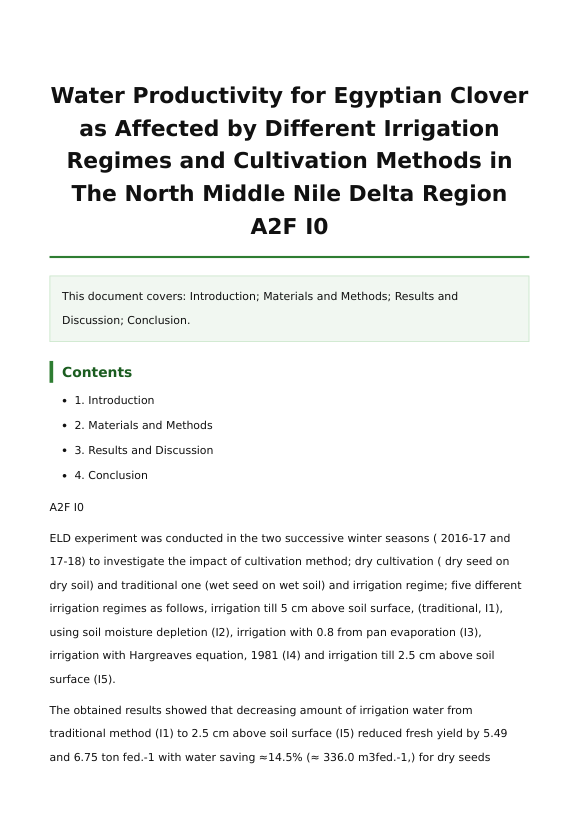

Extracted text, page 2:
 cultivation method, and the corresponding values 4.87 and 7.34 ton fed.-1 with water
saving 10.75% (≈ 280.0 m3fed.-1,) for wet cultivation one in the overall seasons.
Meaningfully, an average of ≈ 700-840 million m3 water could be saved at the
national level (≈2.5 million fed.). Moreover, mean reduction in dry yield by 24.62 kg
fed.-1, (6.35 %) and 13.00 kg fed-1 (3.51 %) could be resulted from dry cultivation
method, and by 36.45 kg fed-1 (8.68 %) and 10.91 kg fed-1 (2.60 %) could be resulted
from wet cultivation method in the first and second seasons respectively.
The highest overall mean values of water consumptive use (CU) and consumptive use
efficiency (Ecu, %) were recorded irrigation without any stress during the growing
season (I1). Productivity of irrigation water (PIW kgm-3) and water productivity (WP
kgm-3) for fresh yield was the highest values recorded under I5 (the lowest water
consumed) for dry and wet cultivation methods.
Keywords: Irrigation re

In [12]:
from IPython.display import Image, display

TEST_FILE = ""   # e.g. "نشرة-دوار-الشمس.pdf"; empty = the first PDF in the folder

test_path = INPUT_DIR / TEST_FILE if TEST_FILE else pdf_files()[0]
result = process_pdf(test_path)
print(test_path.name, "→", json.dumps({k: v for k, v in result.items() if k != "trace"}, ensure_ascii=False, indent=1))
if result["status"] == "done":
    with pymupdf.open(OUTPUT_DIR / test_path.name) as d:
        display(Image(d[0].get_pixmap(dpi=70).tobytes("png")))
        print("Extracted text, page 2:\n", d[min(1, d.page_count - 1)].get_text()[:1200])

## 5. Run all PDFs
Safe to re-run: finished files are skipped.

In [13]:
run_all()

1 duplicate file(s) will be copied instead of processed again.
[1/50] 1-2.pdf: already done
[2/50] 1-نشرة-بنجر-السكر_compressed.pdf: done  28 → 26 pages, 63 sections, 10.5s
[3/50] 135905761430.pdf: done  72 → 96 pages, 7 sections, 6.9s
[4/50] 2-البحث-الثاني.pdf: done  7 → 15 pages, 2 sections, 3.6s
[5/50] 2.pdf: done  7 → 21 pages, 3 sections, 5.2s
[6/50] 577137840-agriculture.pdf: done  10 → 14 pages, 12 sections, 2.9s
[7/50] 917873240-Key-Fact.pdf: done  185 → 286 pages, 78 sections, 37.6s
[8/50] AGRI_008.pdf: done  12 → 9 pages, 9 sections, 2.5s
[9/50] AGRI_011_PDF.pdf: done  49 → 44 pages, 18 sections, 2.5s
[10/50] AGRI_013.pdf: done  73 → 83 pages, 2 sections, 11.3s
[11/50] AGRI_014_PDF.pdf: done  2 → 4 pages, 7 sections, 1.9s
[12/50] AGRI_021.pdf: done  135 → 133 pages, 7 sections, 14.2s
[13/50] Agricultural_RAG_200_Pages_Arabic.pdf: done  200 → 315 pages, 1428 sections, 40.2s
[14/50] cd7067en.pdf: done  148 → 297 pages, 306 sections, 49.9s
[15/50] farmerbook.pdf: done  134 → 200

## 6. Check the results

In [14]:
for p in pdf_files():
    e = manifest.get(p.name, {})
    if e.get("status") == "done":
        print(f"OK     {p.name}: {e['pages_in']} → {e['pages_out']} pages, {e['sections']} sections, "
              f"dropped pages {e['dropped_pages']} | {e.get('title', '')}")
    elif e.get("status") == "error":
        print(f"ERROR  {p.name}: {e['error'][:200]}")
    else:
        print(f"--     {p.name}: not processed yet")

def preview(name, page=1, chars=1500):
    """Show a page of a new PDF and the text a PDF loader gets from it."""
    with pymupdf.open(OUTPUT_DIR / name) as d:
        display(Image(d[page - 1].get_pixmap(dpi=70).tobytes("png")))
        print(d[page - 1].get_text()[:chars])

# preview("نشرة-دوار-الشمس.pdf", page=3)

OK     1-2.pdf: 11 → 23 pages, 4 sections, dropped pages [] | Water Productivity for Egyptian Clover as Affected by Different Irrigation Regimes and Cultivation Methods in The North Middle Nile Delta Region A2F I0
OK     1-نشرة-بنجر-السكر_compressed.pdf: 28 → 26 pages, 63 sections, dropped pages [1, 2, 28] | زراعة وإنتاج بنجر السكر
OK     135905761430.pdf: 72 → 96 pages, 7 sections, dropped pages [1, 2] | AGRICULTURAL KNOWLEDGE AND INFORMATION SYSTEMS AND POVERTY REDUCTION Julio A. Berdegué and Germán Escobar RIMISP
OK     2-البحث-الثاني.pdf: 7 → 15 pages, 2 sections, dropped pages [] | Evaluation of Some Organic Wastes as Growing Media for Promoting Growth of Date Palm (Phoenix dactylifera L.) Plantlets during Acclimatization Stage 1Lobna M. Abdel-Galeil; 2I.M. Yahi and 2M.M.I Afifi 1Central …
OK     2.pdf: 7 → 21 pages, 3 sections, dropped pages [] | Effect of Magnetic Irrigation Water and Nitrogen Fertilizer Forms on Maize (Zea maize L.) Growth, Yield and Nitrogen Utilization Rate. 

## 7. Replace the originals
Copies every finished PDF over the original with the same name. Files that are not finished, or had errors, are left untouched. With `KEEP_BACKUP = True` the originals are kept in `<folder>_originals_backup` (outside your RAG folder, so they are not indexed twice). Set it to `False` to simply overwrite them. Keep the `…_clean` folder afterwards: its manifest is how the notebook knows the replaced files are already clean.

In [15]:
def replace_originals():
    files = pdf_files()
    ready = [p for p in files if manifest.get(p.name, {}).get("status") == "done" and (OUTPUT_DIR / p.name).exists()]
    pending = [p.name for p in files if p not in ready]
    replaced, failed = 0, []
    for p in ready:
        new = OUTPUT_DIR / p.name
        if file_sha1(p) == file_sha1(new):
            continue                                    # already replaced
        try:
            if KEEP_BACKUP and not (BACKUP_DIR / p.name).exists():
                BACKUP_DIR.mkdir(exist_ok=True)
                shutil.copy2(p, BACKUP_DIR / p.name)
            shutil.copyfile(new, p)
            replaced += 1
        except OSError as e:                            # e.g. the PDF is open in another program
            failed.append(f"{p.name}: {e}")
    print(f"Replaced {replaced} PDF(s) in {INPUT_DIR}")
    if KEEP_BACKUP and replaced:
        print(f"Originals backed up in {BACKUP_DIR}")
    if pending:
        print(f"Left untouched (not finished): {pending}")
    if failed:
        print("Could not replace (close them and run again):", *failed, sep="\n  ")

replace_originals()

Replaced 51 PDF(s) in D:\RAG-20261102T133823Z-1-001
Originals backed up in D:\RAG-20261102T133823Z-1-001_originals_backup
